## Imports

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import pm4py
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, confusion_matrix, classification_report)
from collections import defaultdict
from pm4py.algo.conformance.alignments.petri_net import algorithm as alignments
from pm4py.objects.petri_net.semantics import execute
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score, StratifiedKFold
from pm4py.objects.process_tree.obj import ProcessTree, Operator
from pm4py.objects.conversion.process_tree import converter as pt_conv

## Data Integration

In [2]:
if not os.path.exists("bpi_2017.parquet"):
    pm4py.convert_to_dataframe(pm4py.read_xes("BPI Challenge 2017.xes")).to_parquet("bpi_2017.parquet")

df = pd.read_parquet("bpi_2017.parquet")
df = df.sort_values(["case:concept:name", "time:timestamp"], kind="stable").reset_index(drop=True)

## Simple Event Log Analysis

In [3]:
df.head()

,Action,org:resource,concept:name,EventOrigin,EventID,lifecycle:transition,time:timestamp,case:LoanGoal,case:ApplicationType,case:concept:name,case:RequestedAmount,FirstWithdrawalAmount,NumberOfTerms,Accepted,MonthlyCost,Selected,CreditScore,OfferedAmount,OfferID
0,Created,User_1,A_Create Application,Application,Application_1000086665,complete,2016-08-03 15:57:21.673+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,None,NaN,None,NaN,NaN,NaN
1,statechange,User_1,A_Submitted,Application,ApplState_161925113,complete,2016-08-03 15:57:21.734+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,None,NaN,None,NaN,NaN,NaN
2,Created,User_1,W_Handle leads,Workflow,Workitem_747707399,schedule,2016-08-03 15:57:21.963+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,None,NaN,None,NaN,NaN,NaN
3,Deleted,User_1,W_Handle leads,Workflow,Workitem_1030261128,withdraw,2016-08-03 15:58:28.286+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,None,NaN,None,NaN,NaN,NaN
4,Created,User_1,W_Complete application,Workflow,Workitem_1127124826,schedule,2016-08-03 15:58:28.293+00:00,"Other, see explanation",New credit,Application_1000086665,5000.0,NaN,NaN,None,NaN,None,NaN,NaN,NaN


### Statistics (3.2)

In [4]:
from event_log_statistics import run
pt, df_complete, df_model, outcome = run(df, out_dir="results")

# Statistics for the full log, the cases based on valid outcomes and the log with only completed events

In [5]:
outcome.value_counts()

# 98 non-complete cases -> Dropped

outcome
A_Pending        17228
A_Cancelled      10431
A_Denied          3752
Not-Completed       98
Name: count, dtype: int64

In [6]:
# Missing activities in the model log

full = set(df_complete["concept:name"].unique())
model = set(df_model["concept:name"].unique())
missing = full - model
print(missing)

(df_complete[df_complete["concept:name"].isin(missing)]
   .groupby("concept:name")
   .agg(cases=("case:concept:name", "nunique"),
        transitions=("lifecycle:transition", lambda s: sorted(s.unique()))))

# Refer to workflows of specific cases and make out 76 / 31.411 cases -> Dropped

{'W_Shortened completion ', 'W_Personal Loan collection'}


,cases,transitions
concept:name,,
W_Personal Loan collection,2,"[resume, schedule, start, suspend]"
W_Shortened completion,74,"[resume, schedule, start, suspend]"


#### Visualizations

In [57]:
# Initial Setup

CASE_ID = "case:concept:name"
ACTIVITY = "concept:name"
TS = "time:timestamp"
OUTCOMES = ["A_Pending", "A_Denied", "A_Cancelled"]
out_dir = "results"
os.makedirs(out_dir, exist_ok=True)

# outcome per case: last outcome activity, or "Not-Completed" if none
last = (df[df[ACTIVITY].isin(OUTCOMES)]
        .sort_values(TS).groupby(CASE_ID)[ACTIVITY].last())
outcome = last.reindex(df[CASE_ID].unique()).fillna("Not-Completed")

# case duration in days
g = df.groupby(CASE_ID)[TS]
dur = (g.max() - g.min()).dt.total_seconds() / 86400


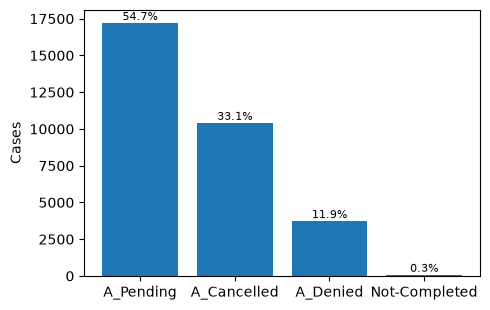

In [58]:
# Application Outcome Distribution 

counts = outcome.value_counts()

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(counts.index, counts.values)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v / counts.sum():.1%}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Cases")
fig.tight_layout()
fig.savefig(os.path.join(out_dir, "fig_outcomes.pdf"))
plt.show()

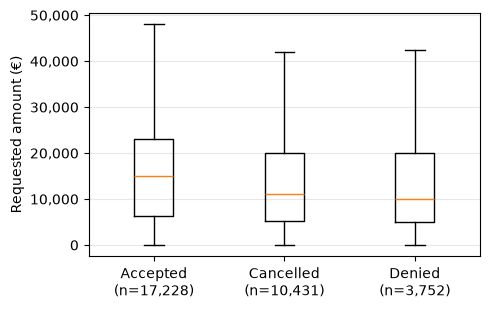

,count,mean,median,std
outcome,,,,
A_Pending,17228.0,16532.0,15000.0,15693.0
A_Cancelled,10431.0,15916.0,11000.0,14860.0
A_Denied,3752.0,15560.0,10000.0,15496.0


In [59]:
# Requested amount by application outcome (one value per case)
cases = (df_model.drop_duplicates("case:concept:name")
         .set_index("case:concept:name")[["case:RequestedAmount"]]
         .join(outcome.rename("outcome")))

order = ["A_Pending", "A_Cancelled", "A_Denied"]
labels = ["Accepted", "Cancelled", "Denied"]
data = [cases.loc[cases["outcome"] == o, "case:RequestedAmount"] for o in order]

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, 4), [f"{l}\n(n={len(d):,})" for l, d in zip(labels, data)])
ax.set_ylabel("Requested amount (€)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("results/fig_requested_amount_by_outcome.pdf")
plt.show()

# numbers for the report text
cases.groupby("outcome")["case:RequestedAmount"].describe()[["count", "mean", "50%", "std"]] \
     .rename(columns={"50%": "median"}).loc[order].round(0)

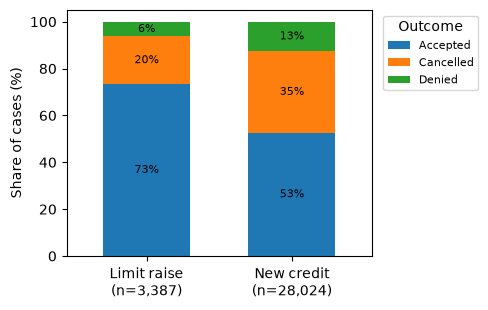

,Accepted,Cancelled,Denied
case:ApplicationType,,,
Limit raise,73.4,20.3,6.3
New credit,52.6,34.8,12.6


In [60]:
order = ["A_Pending", "A_Cancelled", "A_Denied"]
labels = ["Accepted", "Cancelled", "Denied"]

app = (df_model.drop_duplicates("case:concept:name")
       .set_index("case:concept:name")["case:ApplicationType"]
       .to_frame().join(outcome.rename("outcome")))
app = app[app["outcome"].isin(order)]

ct = pd.crosstab(app["case:ApplicationType"], app["outcome"], normalize="index")[order] * 100
ct.columns = labels
n = app["case:ApplicationType"].value_counts()

fig, ax = plt.subplots(figsize=(5, 3.2))
ct.plot(kind="bar", stacked=True, ax=ax, width=0.6)
ax.set_xticklabels([f"{t}\n(n={n[t]:,})" for t in ct.index], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Share of cases (%)")
ax.legend(title="Outcome", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", label_type="center", fontsize=8)
fig.tight_layout()
fig.savefig("results/fig_outcome_by_application_type.pdf")
plt.show()

ct.round(1)

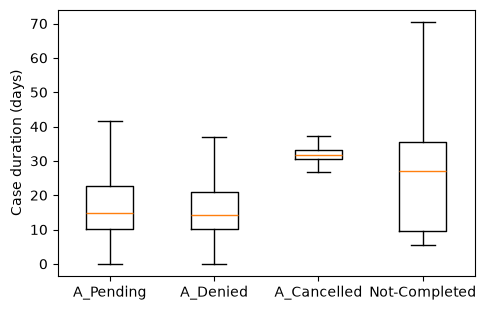

In [61]:
# Case Duration w.r.t. Case Outcome

names = [o for o in OUTCOMES + ["Not-Completed"] if (outcome == o).any()]
data = [dur.loc[outcome[outcome == o].index] for o in names]

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(names) + 1), names)
ax.set_ylabel("Case duration (days)")
fig.tight_layout()
fig.savefig(os.path.join(out_dir, "fig_duration_by_outcome.pdf"))
plt.show()

### Variants

In [25]:
# Most frequent process instances (Only observing complete cases to avoid lifecycle noise (initially only))

# Grouped by case id and displays variants and how many unique cases follow each sequence
variants = pm4py.get_variants(df_model)
top = sorted(variants.items(), key=lambda x: x[1], reverse=True)[:10]

# Number of unique cases
n_cases = df_model["case:concept:name"].nunique()
for i, (var, cnt) in enumerate(top, 1):
    print(f"#{i}  {cnt} cases ({cnt/n_cases:.1%}), {len(var)} events")
    print("   " + " → ".join(var))

#1  2209 cases (7.0%), 11 events
   A_Create Application → A_Submitted → A_Concept → A_Accepted → O_Create Offer → O_Created → O_Sent (mail and online) → W_Complete application → A_Complete → A_Cancelled → O_Cancelled
#2  1917 cases (6.1%), 10 events
   A_Create Application → A_Submitted → A_Concept → A_Accepted → O_Create Offer → O_Created → O_Sent (mail and online) → A_Complete → A_Cancelled → O_Cancelled
#3  1578 cases (5.0%), 10 events
   A_Create Application → A_Concept → A_Accepted → O_Create Offer → O_Created → O_Sent (mail and online) → W_Complete application → A_Complete → A_Cancelled → O_Cancelled
#4  969 cases (3.1%), 12 events
   A_Create Application → A_Concept → A_Accepted → O_Create Offer → O_Created → O_Sent (mail and online) → W_Complete application → A_Complete → A_Validating → O_Returned → O_Accepted → A_Pending
#5  676 cases (2.2%), 12 events
   A_Create Application → A_Submitted → A_Concept → A_Accepted → O_Create Offer → O_Created → O_Sent (mail and online) → A_Co

## Process Discovery

### Discovery Algorithms (3.3.1)

#### IMF

In [13]:
# Inductive Miner

from pm4py.algo.evaluation.generalization import algorithm as generalization_eval
from pm4py.algo.evaluation.simplicity import algorithm as simplicity_eval

log_model = pm4py.convert_to_event_log(df_model)   # Some evaluators (generlaization) need an EventLog object

def is_sound(net, im, fm):
    s = pm4py.check_soundness(net, im, fm)
    return s[0] if isinstance(s, tuple) else s

# Running an IMF model on completed cases with diff noise thresholds
rows = []
for nt in [0.0, 0.05, 0.1, 0.2, 0.4]:
    net, im, fm = pm4py.discover_petri_net_inductive(df_model, noise_threshold=nt)
    fit = pm4py.fitness_token_based_replay(df_model, net, im, fm) # Fitness: share of perfectly replayed traces and overall log fitness
    rows.append({
        "noise": nt,
        "fitting_traces_%": fit["percentage_of_fitting_traces"],
        "log_fitness": fit["log_fitness"],
        "precision": pm4py.precision_token_based_replay(df_model, net, im, fm), # Precision: how little extra behavior the model allows
        "generalization": generalization_eval.apply(log_model, net, im, fm), # Generalization: how likely the model is to accept unseen (but valid) behavior
        "simplicity": simplicity_eval.apply(net), # Simplicity: measuring how simple a model is
        "transitions": len(net.transitions), # Number of transitions
        "silent_transitions": sum(t.label is None for t in net.transitions), # Number of silent transitions
        "places": len(net.places), # Number of places
        "arcs": len(net.arcs), # Number of arcs
        "sound": is_sound(net, im, fm), # Soundness: No dead transitions, proper completion, option to complete
    })

sweep = pd.DataFrame(rows).round(3)
sweep.to_csv("results/imf_noise_sweep.csv", index=False)
sweep

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)
/Users/ziadbahgat/miniforge3/envs/bpic17/lib/python3.12/site-packages/pm4py/algo/analysis/woflan/place_invariants/utility.py:163: UserWarning: solution from scipy may be unstable. Please install PuLP (pip install pulp) for fully reliable results.
  warnings.warn(


replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

... (11 outputs left out)

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)
/Users/ziadbahgat/miniforge3/envs/bpic17/lib/python3.12/site-packages/pm4py/algo/analysis/woflan/place_invariants/utility.py:163: UserWarning: solution from scipy may be unstable. Please install PuLP (pip install pulp) for fully reliable results.
  warnings.warn(


,noise,fitting_traces_%,log_fitness,precision,generalization,simplicity,transitions,silent_transitions,places,arcs,sound
0,0.00,100.000,1.000,0.293,0.959,0.617,53,29,34,114,True
1,0.05,89.357,0.996,0.393,0.987,0.631,52,29,30,106,True
2,0.10,92.181,0.998,0.392,0.990,0.645,44,22,25,88,True
3,0.20,73.621,0.990,0.337,0.980,0.632,49,25,30,102,True
4,0.40,30.193,0.950,0.361,0.954,0.615,42,18,25,88,True


In [14]:
# Optimal IMF

NOISE = 0.1

net_imf, im_imf, fm_imf = pm4py.discover_petri_net_inductive(df_model, noise_threshold=NOISE) # Training IMF with chosen NOISE parameter
pm4py.save_vis_petri_net(net_imf, im_imf, fm_imf, f"results/model_imf_{NOISE}.pdf") # Petri Net
pm4py.write_bpmn(pm4py.convert_to_bpmn(net_imf, im_imf, fm_imf), f"results/model_imf_{NOISE}.bpmn") # BPMN

# Share of replayed traces and overall fitness higher than the rest (except noise = 0)
# Good precision generalization tradeoff compared to other models while maintaining relatively high simplicity

#### Heuristic Miner

In [15]:
# Heuristic Miner

rows = []
for dep in [0.5, 0.9, 0.99]:
    net, im, fm = pm4py.discover_petri_net_heuristics(
        df_model, dependency_threshold=dep, and_threshold=0.65, loop_two_threshold=0.5) # AND_threshold: decides when two branches after an activity count as parallel rather than choice 
    fit = pm4py.fitness_token_based_replay(df_model, net, im, fm)
    rows.append({
        "dependency_threshold": dep, # Dependency: keeps relations with high dependency scores
        "fitting_traces_%": fit["percentage_of_fitting_traces"],
        "log_fitness": fit["log_fitness"],
        "precision": pm4py.precision_token_based_replay(df_model, net, im, fm),
        "generalization": generalization_eval.apply(log_model, net, im, fm),
        "simplicity": simplicity_eval.apply(net),
        "transitions": len(net.transitions),
        "silent_transitions": sum(t.label is None for t in net.transitions),
        "places": len(net.places),
        "arcs": len(net.arcs),
        "sound": is_sound(net, im, fm),
    })

hm_sweep = pd.DataFrame(rows).round(3)
hm_sweep.to_csv("results/heuristics_sweep.csv", index=False)
hm_sweep

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

... (3 outputs left out)

replaying log with TBR, completed traces ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


,dependency_threshold,fitting_traces_%,log_fitness,precision,generalization,simplicity,transitions,silent_transitions,places,arcs,sound
0,0.50,0.0,0.834,0.998,0.851,0.491,88,64,49,208,False
1,0.90,0.0,0.838,0.996,0.865,0.502,89,65,46,202,False
2,0.99,0.0,0.846,0.996,0.899,0.518,77,53,41,173,False


In [16]:
DEP = 0.99
HM_PARAMS = dict(dependency_threshold=DEP, and_threshold=0.99, loop_two_threshold=0.5) # Empirical threshold values (Weijters and van der Aalst) that were implemented as defaults in Pm4py

heu_net = pm4py.discover_heuristics_net(df_model, **HM_PARAMS)
pm4py.save_vis_heuristics_net(heu_net, f"results/model_heuristics_net_{DEP}.pdf")

net_hm, im_hm, fm_hm = pm4py.discover_petri_net_heuristics(df_model, **HM_PARAMS)
pm4py.save_vis_petri_net(net_hm, im_hm, fm_hm, f"results/model_heuristics_petri_{DEP}.pdf")

''

### Quality Metrics (3.3.2)

#### Evaluation

In [17]:
from pm4py.algo.evaluation.simplicity import algorithm as simplicity_eval

results_quality = {}
token_based_replay = pm4py.fitness_token_based_replay(df_model, net_imf, im_imf, fm_imf)
results_quality["TBR fitting traces (%)"] = token_based_replay["percentage_of_fitting_traces"]
results_quality["TBR log fitness"] = token_based_replay["log_fitness"]
for _col, _variant in [("Ext. Cardoso", simplicity_eval.Variants.EXTENDED_CARDOSO),
                       ("Ext. cyclomatic", simplicity_eval.Variants.EXTENDED_CYCLOMATIC)]:
    results_quality[_col] = simplicity_eval.apply(net_imf, variant=_variant)
pd.DataFrame([results_quality], index=["IMf (noise 0.1)"]).round(3)

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

,TBR fitting traces (%),TBR log fitness,Ext. Cardoso,Ext. cyclomatic
IMf (noise 0.1),92.181,0.998,35,44


#### Metric 1

In [18]:
# ACD: Average number of arcs attached to the places and transitions where the process splits or merges (width of branching points)

def own_acd(net):
    d = [len(x.in_arcs) + len(x.out_arcs) for x in list(net.places) + list(net.transitions)
         if len(x.in_arcs) > 1 or len(x.out_arcs) > 1]
    return float(np.mean(d)) if d else 0.0

print(f"ACD, IMf (noise 0.1): {own_acd(net_imf):.2f}")

ACD, IMf (noise 0.1): 4.00


#### Metric 2

In [19]:
# CFC: Counts how many ways the process can continue at each split and add them up

def own_cfc(net):
    return (sum(len(p.out_arcs) for p in net.places if len(p.out_arcs) > 1)
            + sum(1 for t in net.transitions if len(t.out_arcs) > 1))

print(f"CFC, IMf (noise 0.1): {own_cfc(net_imf)}")

CFC, IMf (noise 0.1): 35


### Final Process Model (3.3.3)

#### Log Abstraction

In [20]:
# The two O_Sent variants mean the same step and differ only in channel, which is a data
# attribute rather than a control-flow choice -> We merge them to recover behaviour the
# baseline could not express at all (IMf nt=0.1 filtered O_Sent (online only) out entirely
# so 1,785 cases (5.7%) contained a send the mined model had no transition for)

MERGE = {"O_Sent (mail and online)": "O_Sent", "O_Sent (online only)": "O_Sent"}
df_r1 = df_model.copy()
df_r1[ACTIVITY] = df_r1[ACTIVITY].replace(MERGE)
df_r1 = df_r1.sort_values([CASE_ID, TS], kind="stable")
print(f"{df_model[ACTIVITY].nunique()} -> {df_r1[ACTIVITY].nunique()} activities")

24 -> 23 activities


#### Analysis

In [28]:
# Every figure the six refinements rely on so each claimin 3.3.3 can be checked against the log

log_with_context = df_r1.assign(
    previous_activity=df_r1.groupby(CASE_ID)[ACTIVITY].shift(1).fillna("(start)"), # Direct-follows relation (tells us whether ordering constraint is supported)
    next_activity=df_r1.groupby(CASE_ID)[ACTIVITY].shift(-1).fillna("(end)"), # Direct-follows relation (tells us whether ordering constraint is supported)
    position=df_r1.groupby(CASE_ID).cumcount()) # Index of the event inside its case
n_cases = df_r1[CASE_ID].nunique() # Number of cases

# K most common values (percentages) to express how concentrated a relation is
def top_shares(values, k=3):
    return (values.value_counts(normalize=True) * 100).round(1).head(k).to_dict()

def events_of(activity):
    return log_with_context[log_with_context[ACTIVITY] == activity]

def successors_of(activity):
    return log_with_context.loc[log_with_context[ACTIVITY] == activity, "next_activity"]

print(f"modelling log: {len(df_r1):,} events  {n_cases:,} cases  "
      f"{df_r1[ACTIVITY].nunique()} activities\n")

# R1: W_Handle leads only ever appears after A_Submitted and only ever before A_Concept, so it belongs inside the optional A_Submitted block not beside it

print("R1  successors of A_Create Application:", top_shares(successors_of("A_Create Application")))
for activity in ["W_Handle leads", "W_Assess potential fraud"]:
    occurrences = events_of(activity)
    print(f"    {activity}: {len(occurrences):,} occ in {occurrences[CASE_ID].nunique():,} cases"
          f" | prev {top_shares(occurrences['previous_activity'], 2)}"
          f" | next {top_shares(occurrences['next_activity'], 2)}")

# R2: O_Created is followed by O_Sent in the large majority of cases, so the miner's version where an offer can be created and never sent allows behaviour the log almost never shows
# W_Complete application belongs after the send not as an alternative to making an offer
offer_created_successors = successors_of("O_Created")
print(f"\nR2  successors of O_Created ({len(offer_created_successors):,} occ, "
      f"{offer_created_successors.nunique()} distinct): {top_shares(offer_created_successors, 4)}")

WCOMP = "W_Complete application"
wcomp = events_of(WCOMP)
print(f"    {WCOMP}: {len(wcomp):,} occ in {wcomp[CASE_ID].nunique():,} cases "
      f"({wcomp[CASE_ID].nunique()/n_cases*100:.1f}%), "
      f"{len(wcomp)/wcomp[CASE_ID].nunique():.2f} per case")
print(f"      prev {top_shares(wcomp['previous_activity'], 2)}"
      f" | next {top_shares(wcomp['next_activity'], 2)}")

def first_position(activity):
    return (log_with_context[log_with_context[ACTIVITY] == activity]
            .groupby(CASE_ID)["position"].min())

first_wcomp = first_position(WCOMP)
for other in ["O_Sent", "A_Complete"]:
    both = pd.concat([first_wcomp.rename("w"),
                      first_position(other).rename("x")], axis=1).dropna()
    print(f"      vs first {other:<12} ({len(both):,} cases with both): "
          f"before {(both.w < both.x).mean()*100:.1f}%, after {(both.w > both.x).mean()*100:.1f}%")
    
for activity in ["O_Create Offer", "O_Sent"]:
    covered = log_with_context[log_with_context[ACTIVITY] == activity][CASE_ID].nunique()
    print(f"      cases containing {activity:<15}: {covered:,} ({covered/n_cases*100:.1f}%)")

# R3: W_Call after offers is placed after A_Complete

wcall = events_of("W_Call after offers")
a_complete_per_case = df_r1[df_r1[ACTIVITY] == "A_Complete"].groupby(CASE_ID).size()
offers_per_case = df_r1[df_r1[ACTIVITY] == "O_Create Offer"].groupby(CASE_ID).size()
print(f"\nR3  A_Complete per case: {a_complete_per_case.value_counts().to_dict()}")
print(f"    O_Create Offer per case: "
      f"{offers_per_case.value_counts().sort_index().head(4).to_dict()}")
print(f"    W_Call after offers: {len(wcall):,} complete events of "
      f"{(df[ACTIVITY] == 'W_Call after offers').sum():,} raw events"
      f" | prev {top_shares(wcall['previous_activity'], 2)}"
      f" | next {top_shares(wcall['next_activity'], 2)}")

# R4: Of every case that reaches validation, almost all of them start it with A_Validating The entry can therefore be fixed
# The count comparison on the last line shows why the inside also contains it beause there are far more validation events than A_Validating events, so one A_Validating 
# per validation event is impossible.

validation_activities = ["W_Validate application", "W_Call incomplete files", "O_Returned",
                         "A_Incomplete", "O_Accepted", "A_Denied", "O_Refused",
                         "W_Assess potential fraud"]
first_validation_activity = (
    log_with_context[log_with_context[ACTIVITY].isin(validation_activities + ["A_Validating"])]
    .sort_values([CASE_ID, "position"]).groupby(CASE_ID)[ACTIVITY].first())
print(f"\nR4  cases reaching validation: {len(first_validation_activity):,} "
      f"({len(first_validation_activity)/n_cases*100:.1f}%)")
print(f"    first validation activity: {top_shares(first_validation_activity, 3)}")
print(f"    A_Validating occurrences {(df_r1[ACTIVITY] == 'A_Validating').sum():,} vs other "
      f"validation activities {df_r1[ACTIVITY].isin(validation_activities).sum():,}")

# R5: The rework activities each have many different successors and no dominant one, so there is no evidence for fixing their order
# The two outcome pairs are near deterministic so they become sequences.
print("\nR5  successor spread inside validation (the case for leaving rework unordered):")
for activity in ["A_Validating", "O_Returned", "A_Incomplete", "W_Validate application"]:
    successors = successors_of(activity)
    top3 = (successors.value_counts(normalize=True) * 100).head(3).sum()
    print(f"    {activity:24s} {len(successors):>6,} occ  "
          f"{successors.nunique():>2} distinct successors  top3 {top3:.1f}%")
for activity, expected_successor in [("O_Accepted", "A_Pending"), ("A_Denied", "O_Refused")]:
    successors = successors_of(activity)
    print(f"    {activity} -> {expected_successor}: "
          f"{(successors == expected_successor).mean()*100:.2f}% of {len(successors):,} occurrences")

# R6: No case takes a second decision, creates a new offer, or re-enters validation after terminal events. What follows is a single work item that was already
# open and completes late which is why R6 uses one optional closing step instead of R5's loop back into rework
outcome_activities = ["A_Pending", "A_Denied", "A_Cancelled"]
first_outcome_position = (log_with_context[log_with_context[ACTIVITY].isin(outcome_activities)]
                          .groupby(CASE_ID)["position"].min().rename("first_outcome"))
after_outcome = log_with_context.join(first_outcome_position, on=CASE_ID)
after_outcome = after_outcome[after_outcome["position"] > after_outcome["first_outcome"]]
outcome_types_per_case = (log_with_context[log_with_context[ACTIVITY].isin(outcome_activities)]
                          .groupby(CASE_ID)[ACTIVITY].nunique())
print(f"\nR6  cases with exactly one outcome type: {(outcome_types_per_case == 1).mean()*100:.1f}%")
print(f"    re-opening after the outcome  (O_Create Offer): "
      f"{after_outcome[after_outcome[ACTIVITY] == 'O_Create Offer'][CASE_ID].nunique():,} cases")
print(f"    re-entering validation        (A_Validating):   "
      f"{after_outcome[after_outcome[ACTIVITY] == 'A_Validating'][CASE_ID].nunique():,} cases")
work_item_tails = (after_outcome[after_outcome[ACTIVITY].str.startswith("W_")]
                   .groupby(CASE_ID)[ACTIVITY].apply(lambda s: " > ".join(s)))
print(f"    a W event after the outcome: {len(work_item_tails):,} cases "
      f"({len(work_item_tails)/n_cases*100:.1f}%), "
      f"{work_item_tails.nunique()} distinct W-tails")
print((work_item_tails.value_counts(normalize=True) * 100).round(1).to_string())

modelling log: 473,963 events  31,411 cases  23 activities

R1  successors of A_Create Application: {'A_Submitted': 64.8, 'A_Concept': 35.2}
    W_Handle leads: 3,473 occ in 3,473 cases | prev {'A_Submitted': 99.5, 'W_Assess potential fraud': 0.5} | next {'A_Concept': 100.0}
    W_Assess potential fraud: 282 occ in 268 cases | prev {'O_Refused': 33.0, 'W_Validate application': 25.9} | next {'(end)': 33.0, 'A_Incomplete': 18.8}

R2  successors of O_Created (42,815 occ, 9 distinct): {'O_Sent': 88.7, 'O_Create Offer': 9.1, 'O_Cancelled': 1.8, 'A_Cancelled': 0.3}
    W_Complete application: 19,061 occ in 19,059 cases (60.7%), 1.00 per case
      prev {'O_Sent': 99.6, 'O_Cancelled': 0.2} | next {'A_Complete': 99.6, '(end)': 0.3}
      vs first O_Sent       (18,996 cases with both): before 0.0%, after 100.0%
      vs first A_Complete   (18,996 cases with both): before 100.0%, after 0.0%
      cases containing O_Create Offer : 31,411 (100.0%)
      cases containing O_Sent         : 31,264 (99

#### Refined Models

In [ ]:
# A process tree is block-structured, so every Petri net converted from one is sound by
# construction. Refining the tree keeps soundness

def _n(op, children):
    node = ProcessTree(operator=op)
    for c in children:              # a node holds one parent pointer (can't be reused)
        c.parent = node             # subtree object in two places
        node.children.append(c)
    return node

def act(l):  return ProcessTree(label=l)
def tau():   return ProcessTree()
def seq(*c): return _n(Operator.SEQUENCE, c)
def xor(*c): return _n(Operator.XOR, c)
def loop(body, redo=None): return _n(Operator.LOOP, [body, redo or tau()])
def opt(x):  return xor(x, tau())
def to_net(t): return pt_conv.apply(t, variant=pt_conv.Variants.TO_PETRI_NET)

refine = {} 

In [30]:
# Every refined model is the same skeleton with one phase swapped, so each step states only what it changes, and a fix to a shared part is made once

# Phases
# W_Handle leads only ever follows A_Submitted, so it is nested inside it rather than offered as an independent option the way the miner had it
def intake():
    return opt(seq(act("A_Submitted"), opt(act("W_Handle leads"))))

# sent_inline=False keeps the miner's shape, where O_Sent floats outside the offer sequence and an offer can be created without being sent (from R2 on it must be sent)
def offer(sent_inline=True):
    return (seq(act("O_Create Offer"), act("O_Created"), act("O_Sent")) if sent_inline
            else seq(act("O_Create Offer"), act("O_Created")))

# R3 adds W_Call after offers, which only ever occurs after A_Complete
def complete(wcall=True):
    return (seq(act("A_Complete"), opt(act("W_Call after offers"))) if wcall
            else act("A_Complete"))

# The permissive validation block IMf produced: every validation activity as a free choice inside a loop (the two outcome sequences included as branches of the same XOR)
def flower():
    return loop(xor(act("W_Validate application"), act("W_Call incomplete files"),
                    act("A_Validating"), act("O_Returned"), act("A_Incomplete"),
                    seq(act("O_Accepted"), act("A_Pending")),
                    seq(act("A_Denied"), loop(act("O_Refused"))),
                    act("W_Assess potential fraud")), tau())

# Six rework activities in free order
def rework():
    return loop(xor(act("A_Validating"), act("O_Returned"), act("W_Validate application"),
                    act("A_Incomplete"), act("W_Call incomplete files"),
                    act("W_Assess potential fraud")), tau())

# O_Accepted -> A_Pending is 100% over 17,228 occurrences, A_Denied -> O_Refused 99.1%, so both are sequences rather than free choices (loop() here means one or more)
def outcome():
    return opt(xor(seq(act("O_Accepted"), act("A_Pending")),
                   seq(act("A_Denied"), loop(act("O_Refused")))))

def validation(kind):
    if kind == "flower":                                            # R1 - R3
        return flower()
    if kind == "entry":                                             # R4
        return seq(act("A_Validating"), flower())
    if kind == "split":                                             # R5
        return seq(act("A_Validating"), loop(seq(rework(), outcome()), tau()))
    if kind == "terminal":                                          # R6
        return seq(act("A_Validating"), rework(), outcome(),
                   opt(act("W_Validate application")))
    raise ValueError(kind)

# Zero or more offer cancellations, written as one loop: *(tau, X) (O_Cancelled occurs in 49.9% of cases and 1.33 times per case when it occurs)
def case_tail():
    return [opt(act("A_Cancelled")), loop(tau(), act("O_Cancelled"))]

# Skeleton
# wcomp_xor when true keeps the miner's shape where a round is either completing the application or making an offer although the log shows that every case has an O_Create Offer
# and W_Complete Application is preceded by O_Sent in 99.6% of the 19,061 occurences and followed by A_Complete 99.6% and falls after the first O_Sent in 100% of the cases
def build(val, sent_inline=True, wcall=True, wcomp_xor=False):
    if wcomp_xor:
        body = [xor(act("W_Complete application"), offer(sent_inline))]
        if not sent_inline:
            body.append(opt(loop(act("O_Sent"), tau())))
    else:
        body = [offer(sent_inline)]
        if not sent_inline:
            body.append(opt(loop(act("O_Sent"), tau())))
        body.append(opt(act("W_Complete application")))
    body += [opt(complete(wcall)), opt(validation(val))]
    return seq(act("A_Create Application"), intake(),
               act("A_Concept"), act("A_Accepted"),
               loop(seq(*body), tau()), *case_tail())

# Refined Models
MODELS = {
    "R1 intake nesting": build("flower", sent_inline=False, wcall=False, wcomp_xor=True),
    "R2 offer phase": build("flower", wcall=False),
    "R3 W_Call after offers": build("flower"),
    "R4 validation entry fixed": build("entry"),
    "R5 rework / outcome split": build("split"),
    "R6 terminal decision (FINAL)": build("terminal"),
}
FINAL = "R6 terminal decision (FINAL)"

for _tag, _tree in MODELS.items():
    _n, _i, _f = to_net(_tree) # Petri Net conversion (net, initial marking, final marking) -> block-structured
    refine[_tag] = ((_n, _i, _f), df_r1) # registers model and log it should be scored on (df_model and df_r1 distinguished)
    _k = _tag.split()[0] # first word of label for filename
    pm4py.write_bpmn(pm4py.convert_to_bpmn(_n, _i, _f), f"{out_dir}/{_k}.bpmn")
    pm4py.write_pnml(_n, _i, _f, f"{out_dir}/{_k}.pnml")
    print(f"{_tag:34s} trans {len(_n.transitions):>3}  silent "
          f"{sum(t.label is None for t in _n.transitions):>3}  places {len(_n.places):>3}  "
          f"arcs {len(_n.arcs):>3}  sound {is_sound(_n, _i, _f)}")

tree_final = MODELS[FINAL]
(net_final, im_final, fm_final), _ = refine[FINAL]   # reuse the net already in the table

pm4py.write_bpmn(pm4py.convert_to_bpmn(net_final, im_final, fm_final), f"{out_dir}/final.bpmn")
pm4py.write_pnml(net_final, im_final, fm_final, f"{out_dir}/final.pnml")
print(f"\nBPMN 2.0 and PNML written to {out_dir}/   (final = {FINAL.split()[0]})")

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)
/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


R1 intake nesting                  trans  41  silent  19  places  23  arcs  82  sound True
R2 offer phase                     trans  38  silent  16  places  22  arcs  76  sound True


/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)
/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


R3 W_Call after offers             trans  40  silent  17  places  23  arcs  80  sound True
R4 validation entry fixed          trans  40  silent  16  places  23  arcs  80  sound True


/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)
/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


R5 rework / outcome split          trans  44  silent  20  places  26  arcs  88  sound True
R6 terminal decision (FINAL)       trans  43  silent  18  places  25  arcs  86  sound True

BPMN 2.0 and PNML written to results/   (final = R6)


##### Metrics

In [32]:
from pm4py.algo.evaluation.replay_fitness import algorithm as replay_fitness
from pm4py.algo.evaluation.generalization import algorithm as generalization_eval

refine = {"R0   IMf nt0.1 (mined baseline)": ((net_imf, im_imf, fm_imf), df_model), **refine}

refine_results = {}
for name, ((net, im, fm), log) in refine.items():
    print(f"{name} ...", flush=True)
    r = refine_results[name] = {"activities": log[ACTIVITY].nunique()}
    aligned = pm4py.conformance_diagnostics_alignments(log, net, im, fm)
    af = replay_fitness.evaluate(aligned, variant=replay_fitness.Variants.ALIGNMENT_BASED)
    r["Align fitting traces (%)"] = af["percentage_of_fitting_traces"]
    r["Align log fitness"] = af["log_fitness"]
    tbr = pm4py.fitness_token_based_replay(log, net, im, fm)
    r["TBR fitting traces (%)"] = tbr["percentage_of_fitting_traces"]
    r["TBR gap (pp)"] = tbr["percentage_of_fitting_traces"] - r["Align fitting traces (%)"]
    r["Align precision"] = pm4py.precision_alignments(log, net, im, fm)
    r["Generalization"] = generalization_eval.apply(pm4py.convert_to_event_log(log), net, im, fm)
    r["Simplicity (arc degree)"] = simplicity_eval.apply(
        net, variant=simplicity_eval.Variants.SIMPLICITY_ARC_DEGREE)
    r["ACD (own)"] = own_acd(net)
    r["CFC (own)"] = own_cfc(net)
    r["transitions"] = len(net.transitions)
    r["silent"] = sum(t.label is None for t in net.transitions)
    r["arcs"] = len(net.arcs)
    r["sound"] = is_sound(net, im, fm)

refinement = pd.DataFrame(refine_results).T
refinement.to_csv(f"{out_dir}/refinement_steps.csv")
refinement.round(3)

R0   IMf nt0.1 (mined baseline) ...


aligning log, completed variants ::   0%|          | 0/5562 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/27735 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5562 [00:00<?, ?it/s]

R1 intake nesting ...


... (33 outputs left out)

computing precision with alignments, completed variants ::   0%|          | 0/25182 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::   0%|          | 0/5196 [00:00<?, ?it/s]

/var/folders/th/y1fmdjjn7lz5dk4zc6kppjw80000gn/T/ipykernel_11769/1667753778.py:9: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  s = pm4py.check_soundness(net, im, fm)


,activities,Align fitting traces (%),Align log fitness,TBR fitting traces (%),TBR gap (pp),Align precision,Generalization,Simplicity (arc degree),ACD (own),CFC (own),transitions,silent,arcs,sound
R0 IMf nt0.1 (mined baseline),24,86.886759,0.991115,92.181083,5.294324,0.400249,0.990233,0.64486,4.0,35,44,22,88,True
R1 intake nesting,23,91.872274,0.994845,92.798701,0.926427,0.383016,0.990313,0.64,4.111111,32,41,19,82,True
R2 offer phase,23,82.980485,0.983731,83.830505,0.850021,0.446766,0.989862,0.652174,4.125,28,38,16,76,True
R3 W_Call after offers,23,83.528063,0.984032,83.528063,0.0,0.452111,0.988875,0.649485,4.117647,30,40,17,80,True
R4 validation entry fixed,23,81.678393,0.982816,52.994174,-28.684219,0.588393,0.963919,0.649485,4.117647,30,40,16,80,True
R5 rework / outcome split,23,81.261342,0.982344,25.051733,-56.209608,0.59747,0.985964,0.660377,3.9,33,44,20,88,True
R6 terminal decision (FINAL),23,80.68511,0.982021,49.864697,-30.820413,0.610521,0.965591,0.653846,4.0,33,43,18,86,True


### Decision Mining (3.3.4)

In [53]:
# Alignment-based rather than token replay. Token replay cannot use the ~19% of traces that do not fit and cant see past a chain of silent transitions
# after a decision point. Aligning fixes both: the next sync move after the decision point is the label. 
# Leakage in 'Accepted' and 'Selected' on O_Create Offer events since they record whether the offer was eventually accepted so both are excluded

CASE_ATTRS  = ["case:RequestedAmount", "case:ApplicationType", "case:LoanGoal"]
OFFER_ATTRS = ["CreditScore", "OfferedAmount", "NumberOfTerms", "MonthlyCost",
               "FirstWithdrawalAmount"]
STATE_FEATS = ["n_events", "n_offers", "n_validations", "n_sent", "a_complete_done",
               "days_elapsed"]

# Feature vector after every prefix length (one pass over the trace) shwoing features that are available at that point and can be used
def prefix_states(case_events):
    case_level = {a.replace("case:", ""): case_events.iloc[0][a] for a in CASE_ATTRS}
    state = dict(case_level, n_events=0, n_offers=0, n_validations=0, n_sent=0,
                 a_complete_done=0, days_elapsed=0.0,
                 **{a: np.nan for a in OFFER_ATTRS})
    states, start_time = [state], case_events[TS].iloc[0]

    # Element i is what was known about the case after its first i events
    for i, (activity, timestamp, event_attrs) in enumerate(
            zip(case_events[ACTIVITY], case_events[TS],
                case_events[OFFER_ATTRS].to_dict("records")), start=1):
        state = dict(state, n_events=i,
                     days_elapsed=round((timestamp - start_time).total_seconds() / 86400, 3))
        state["n_offers"] += (activity == "O_Create Offer")
        state["n_validations"] += (activity == "A_Validating")
        state["n_sent"] += (activity == "O_Sent")
        state["a_complete_done"] |= (activity == "A_Complete")
        for attr in OFFER_ATTRS:                 # carry the latest non-null value of offer attributes forward
            value = event_attrs[attr]
            if value is not None and value == value:     # False for NaN
                state[attr] = value
        states.append(state)
    return states

# Align the log, replay each aligned path and record which branch every case took at every decision point, together with what was known about it at that moment
def mine_decisions(log, net, initial_marking, final_marking):
    transition_by_name = {t.name: t for t in net.transitions}
    # Builds decision points (places with more than one outgoing arc)
    decision_points = {
        place: sorted({(arc.target.label or "tau:" + arc.target.name)
                       for arc in place.out_arcs})
        for place in net.places if len(place.out_arcs) > 1}
    event_log = pm4py.convert_to_event_log(log)
    Params = alignments.Variants.VERSION_STATE_EQUATION_A_STAR.value.Parameters # One of PM4Py alignment implementations (eum members from Parameters used as keys for the parameters dict)
    # Converting dataframe to an event log and run alignment
    aligned = alignments.apply(
        event_log, net, initial_marking, final_marking,
        parameters={Params.PARAM_ALIGNMENT_RESULT_IS_SYNC_PROD_AWARE: True}) # Sates which transitions were taken not only activity labels
    print(f"{len(decision_points)} decision points | {len(aligned):,} cases aligned",
          flush=True)

    events_by_case = dict(tuple(log.groupby(CASE_ID)))
    observations = defaultdict(list) # Dict creating an empty list for keys

    for trace, alignment in zip(event_log, aligned):
        case_id = trace.attributes["concept:name"]
        states = prefix_states(events_by_case[case_id])
        marking, log_index = initial_marking, 0 # Reset per case (marking is where the token is and log index is how many real events have happened)

        # Each step is ((log event name, transition name), (log label, model label)) which corresponds to name_pair and label_pair
        for name_pair, label_pair in alignment["alignment"]:
            transition_name = name_pair[1]

            if transition_name == ">>": # Log move (log did something that model has no transition for)
                log_index += 1 # Advance in the log (net remains untouched)
                continue

            transition = transition_by_name.get(transition_name) # Turns name back to actual transition object
            if transition is None:
                continue

            # Before firing, every currently marked place that is a decision point and offers this transition is a choice the case is resolving right now
            # Marking is iterable over its marked places
            for place in marking:
                if place in decision_points and any(arc.target is transition for arc in place.out_arcs):
                    features = states[min(log_index, len(states) - 1)] # Feature snapshot at this point
                    branch = transition.label or "tau:" + transition.name
                    observations[place].append((features, branch))

            marking = execute(transition, net, marking) # Fires the transition
            if marking is None: # Alignment inconsistent with the net
                break

            # Advance in the log only on a synchronous move. A silent model move consumes no log event, so the feature vector must not move with it
            log_index += (label_pair[0] != ">>") # Boolean 0 or 1 (>> is a silent move)

    return decision_points, observations


decision_points, observations = mine_decisions(df_r1, net_final, im_final, fm_final)

aligning log, completed variants ::   0%|          | 0/5196 [00:00<?, ?it/s]

14 decision points | 31,411 cases aligned


In [54]:
# Each gateway is fitted twice and the gap between the two fits is the result:
# DATA = case attributes + latest offer parameters -> what a simulator would know about a case
# DATA+STATE = the above plus where the case is in the process -> what the model structure already encodes
# STATE high, DATA low -> structural: the structure already decides this branch so the simulation needs no routing parameter for it
# DATA high -> a data-driven routing rule is justified
# both near chance -> nothing predicts it, the simulation samples a fixed branching probability

# Data preparation for decision tree
def encode_features(features):
    categorical = [c for c in features if not pd.api.types.is_numeric_dtype(features[c])]
    encoded = pd.get_dummies(features, columns=categorical, dummy_na=True) # One-hot dummy encoding of categorical variables
    return encoded.apply(pd.to_numeric, errors="coerce").fillna(-1).astype(float) # Coerced numeric features

# Fit decision tree and measure cross validated accuracy
def fit_and_score(X, y):
    # Scaling min samples leaf with data so small gateways cant split into noise
    # Balanced class weight stops skewed gateway from always predicting majority class
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=max(50, len(y) // 100), class_weight="balanced", random_state=0)
    balanced_acc = cross_val_score(tree, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy").mean()
    return tree.fit(X, y), balanced_acc # Returned tree refitted on everything (not like accuracy score)

summary_rows, rule_text = [], {}
rule_probs = {}

# Largest gateways first so the table reads in order of importance
for place, samples in sorted(observations.items(), key=lambda kv: -len(kv[1])):
    branches_taken = pd.Series([branch for _, branch in samples]) # y
    if branches_taken.nunique() < 2:
        continue
    features = pd.DataFrame([feats for feats, _ in samples]) # X
    data_only = features.drop(columns=[c for c in STATE_FEATS if c in features]) # dropping STATE_FEATS columns (guard: a gateway may never have seen a column)

    encoded_data = encode_features(data_only)      # simulator's view
    encoded_full = encode_features(features)       # including process position

    tree_data, acc_data             = fit_and_score(encoded_data, branches_taken)
    tree_full, acc_data_state       = fit_and_score(encoded_full, branches_taken)

    gateway = " | ".join(decision_points[place])[:70]   # the branches this place offers
    chance = 1 / branches_taken.nunique()              # accuracy of random guessing

    # Thresholds are conventions, chosen so a verdict means something practical
    # +0.10 from state and >0.70 overall = the structure carries the decision
    # +0.15 over chance on data alone = a rule worth writing down
    verdict = ("structural"  if acc_data_state - acc_data > 0.10 and acc_data_state > 0.70 else
               "data-driven" if acc_data - chance > 0.15 else
               "fixed probability")

    summary_rows.append({
        "decision_point": gateway,
        "support":    len(branches_taken),
        "branches":   branches_taken.nunique(),
        "chance":     round(chance, 3),
        "DATA":       round(acc_data, 3),
        "DATA+STATE": round(acc_data_state, 3),
        "gap":        round(acc_data_state - acc_data, 3),
        "verdict":    verdict,
        "majority":   round(branches_taken.value_counts(normalize=True).max(), 3),
    })

    # A guard must come from the fit its verdict is based on. Exporting the
    # data+state tree for a data-driven gateway would write process position
    # (n_events, a_complete_done) into a BPMN condition, which a simulator
    # cannot evaluate and which the structural verdict already covers.
    on_data = verdict == "data-driven"
    rule_text[gateway] = export_text(tree_data if on_data else tree_full,
                                     feature_names=list(encoded_data if on_data else encoded_full),
                                     max_depth=3)
    # branch shares, for the gateways simulated with a fixed probability
    rule_probs[gateway] = branches_taken.value_counts(normalize=True).round(3).to_dict()

decisions = pd.DataFrame(summary_rows)
decisions.to_csv(f"{out_dir}/decision_points.csv", index=False)
open(f"{out_dir}/decision_rules.txt", "w").write(
    "\n\n".join(f"### {name}\n{rule}" for name, rule in rule_text.items()))
open(f"{out_dir}/decision_probs.txt", "w").write(
    "\n".join(f"{k}\n  {v}" for k, v in rule_probs.items())) 
print(decisions.to_string(index=False))

                                                        decision_point  support  branches  chance  DATA  DATA+STATE   gap           verdict  majority
A_Incomplete | A_Validating | O_Returned | W_Assess potential fraud |     74846         6   0.167 0.245       0.340 0.095 fixed probability     0.308
                                             tau:skip_11 | tau:skip_12    74846         2   0.500 0.541       0.611 0.070 fixed probability     0.685
                                             O_Cancelled | tau:skip_26    50364         2   0.500 0.638       0.771 0.133        structural     0.624
                                   W_Complete application | tau:skip_6    42804         2   0.500 0.548       0.741 0.193        structural     0.556
                                               A_Complete | tau:skip_8    42804         2   0.500 0.566       1.000 0.434        structural     0.730
                                            A_Validating | tau:skip_19    42804         2   0.500 0.

In [55]:
# Structural gateways need nothing (the net already decides them). The rest each need one parameter: a guard for data-driven ones and a branching probability for the others

print(decisions.groupby("verdict").agg(gateways=("support", "size"), # how many gateways of this kind
                                       observations=("support", "sum"), # how much evidence behind them
                                       mean_DATA=("DATA", "mean"), # predictable from attributes alone
                                       mean_STATE=("DATA+STATE", "mean")) # predictable with position added
        .round(3).to_string())
print(f"\nrouting parameters the simulation actually needs: "
      f"{(decisions.verdict != 'structural').sum()} of {len(decisions)} gateways\n")

                   gateways  observations  mean_DATA  mean_STATE
verdict                                                         
data-driven               6        203263      0.768       0.806
fixed probability         4        193598      0.494       0.535
structural                4        140543      0.581       0.847

routing parameters the simulation actually needs: 10 of 14 gateways



#### Evaluation

In [56]:
# Open one gateway up: showing which branches the classifier gets right and compares it against two baselines that a reported accuracy can hide behind

def evaluate_gateway(name_contains, use_state=True, depth=3, balanced=True):
    place = next(p for p in observations
                 if name_contains in " | ".join(decision_points[p]))
    samples = observations[place]
    y = pd.Series([branch for _, branch in samples])
    X = pd.DataFrame([feats for feats, _ in samples])
    if not use_state:
        X = X.drop(columns=[c for c in STATE_FEATS if c in X])
    X = encode_features(X)

    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=max(50, len(y) // 100), class_weight="balanced" if balanced else None, random_state=0)
    pred = cross_val_predict(tree, X, y,cv=StratifiedKFold(5, shuffle=True, random_state=0))

    majority = y.value_counts().idxmax()
    print(f"=== {' | '.join(decision_points[place])}")
    print(f"{len(y):,} obs,{y.nunique()} branches, depth {depth}, "
          f"class_weight={'balanced' if balanced else 'none'}\n")
    print(f"balanced accuracy{balanced_accuracy_score(y, pred):.3f}"
          f"(chance {1/y.nunique():.3f})")
    print(f"plain accuracy{accuracy_score(y, pred):.3f}"
          f"(always '{majority}': {(y == majority).mean():.3f})\n")
    print(pd.DataFrame(confusion_matrix(y, pred, labels=sorted(y.unique())), index=[f"actual {b}" for b in sorted(y.unique())], columns=[f"pred {b}" for b in sorted(y.unique())]).to_string())
    print()
    print(classification_report(y, pred, zero_division=0))

evaluate_gateway("A_Cancelled")
evaluate_gateway("A_Denied")
evaluate_gateway("W_Call after offers")          # the 99.2%-majority case
evaluate_gateway("W_Assess potential fraud")     # 6-way, as configured
evaluate_gateway("W_Assess potential fraud", depth=5, balanced=False)  

=== A_Cancelled | tau:skip_22
31,411 obs,2 branches, depth 3, class_weight=balanced

balanced accuracy0.947(chance 0.500)
plain accuracy0.961(always 'tau:skip_22': 0.670)

                    pred A_Cancelled  pred tau:skip_22
actual A_Cancelled              9370              1002
actual tau:skip_22               216             20823

              precision    recall  f1-score   support

 A_Cancelled       0.98      0.90      0.94     10372
 tau:skip_22       0.95      0.99      0.97     21039

    accuracy                           0.96     31411
   macro avg       0.97      0.95      0.96     31411
weighted avg       0.96      0.96      0.96     31411

=== A_Denied | O_Accepted | tau:skip_17
23,567 obs,3 branches, depth 3, class_weight=balanced

balanced accuracy0.696(chance 0.333)
plain accuracy0.804(always 'O_Accepted': 0.731)

                    pred A_Denied  pred O_Accepted  pred tau:skip_17
actual A_Denied              2196              104              1299
actual O_Accepte

In [47]:
df_r1["CreditScore"].value_counts().head()

CreditScore
0.0       27555
904.0       103
943.0       102
1030.0       97
931.0        93
Name: count, dtype: int64

## Comments